<a href="https://colab.research.google.com/github/Shabin2003/Building-from-scratch-with-Pytorch/blob/main/TOY_DATASET_CLASSIFICATION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Dataset Preparation: Toy dataset**

In [ ]:
import torch
import pandas as pd
from sklearn.datasets import make_circles


In [ ]:
n_samples = 1000
X, y = make_circles(n_samples,
                    noise = 0.03,
                    random_state= 42,
                    factor = 0.5)

In [ ]:
len(X),len(y) # Both input and output are 1000 rows each as we set n_samples to 1000

(1000, 1000)

#### **Dataset rows preview**

In [ ]:
print(f"First 10 rows of X: \n{X[:10]}")
print(f"First 10 rows of Y: \n{y[:10]}")

First 10 rows of X: 
[[ 0.46463176  0.15322829]
 [-0.4601531   0.10446773]
 [-0.51775752  0.13568206]
 [-0.26599694  0.42143465]
 [ 0.44220765 -0.89672343]
 [-0.29428848  0.44054824]
 [-0.00987855  0.50337241]
 [ 0.47550749  0.09896844]
 [-0.10940935 -0.49949924]
 [-0.1214858   1.02150905]]
First 10 rows of Y: 
[1 1 1 1 0 1 1 1 1 0]


In [ ]:
# Converting to dataframe
circles = pd.DataFrame({"X1":X[:,0],"X2":X[:,1],"label": y})
circles.head()

,X1,X2,label
0,0.464632,0.153228,1
1,-0.460153,0.104468,1
2,-0.517758,0.135682,1
3,-0.265997,0.421435,1
4,0.442208,-0.896723,0


In [ ]:
circles.label.value_counts()

,count
label,
1,500
0,500


### **Data Visualization**

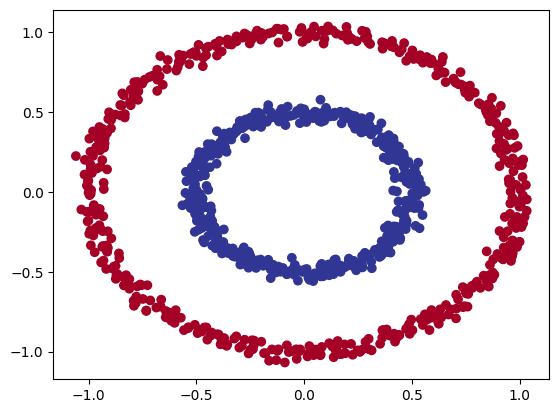

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(x =X[:,0],
            y=X[:,1],
            c=y,
            cmap=plt.cm.RdYlBu
            )


In [ ]:
X.shape, y.shape

((1000, 2), (1000,))

In [ ]:
type(X), type(y)

(numpy.ndarray, numpy.ndarray)

In [ ]:
torch.dtype(X)

TypeError: cannot create 'torch.dtype' instances

#### **Converting dataset to Pytorch tensors**

In [ ]:
X= torch.from_numpy(X).type(torch.float32)
y=torch.from_numpy(y).type(torch.float32)
print("First 5 rows of X: ", X[:5])
print("First 5 rows of y: ",y[:5])


First 5 rows of X:  tensor([[ 0.4646,  0.1532],
        [-0.4602,  0.1045],
        [-0.5178,  0.1357],
        [-0.2660,  0.4214],
        [ 0.4422, -0.8967]])
First 5 rows of y:  tensor([1., 1., 1., 1., 0.])


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
len(X_train),len(X_test),len(y_train),len(y_test)
#

(800, 200, 800, 200)

In [ ]:
import torch
from torch import nn
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:
from torch import nn
class CircleModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1 = nn.Linear(in_features=2, out_features=9)
    self.layer2 = nn.Linear(in_features=9, out_features=18)
    self.layer3 = nn.Linear(in_features=18, out_features=1)

  def forward(self,x):
    return self.layer3(self.layer2(self.layer1(x)))

circle=CircleModel()
circle=circle.to(device)

In [ ]:
model = nn.Sequential(
    nn.Linear(in_features=2, out_features=9),
    nn.Linear(in_features=9, out_features=18),
    nn.Linear(in_features=18, out_features=1)
).to(device)
model

Sequential(
  (0): Linear(in_features=2, out_features=9, bias=True)
  (1): Linear(in_features=9, out_features=18, bias=True)
  (2): Linear(in_features=18, out_features=1, bias=True)
)

In [ ]:
y_logits=model(X_test.to(device))
print(f"\nUntrained model predictions Output tensor dim: {y_logits.shape}")
print(f"\nTrue test outputs dimensions: \n{y_test.shape}")
print(f"\nFirst 10 rows of untrained model predictions: \n{y_logits[:10]}")
print(f"\nFirst 10 rows of True output: {y_test[:10]}")


Untrained model predictions Output tensor dim: torch.Size([200, 1])

True test outputs dimensions: 
torch.Size([200])

First 10 rows of untrained model predictions: 
tensor([[-0.0080],
        [-0.0852],
        [ 0.0795],
        [-0.0854],
        [ 0.1207],
        [ 0.1046],
        [-0.0287],
        [ 0.0221],
        [ 0.0828],
        [-0.0872]], device='cuda:0', grad_fn=<SliceBackward0>)

First 10 rows of True output: tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


### Loss function and Optimizer setup

**Binary Cross Entropy (BCE)** is used since this is a classification problem with only two labels.
- **BCEWithLogitsLoss** solves the numerical instability problem and works directly with unbounded logits.


In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model.parameters(),lr=0.1)

### Accuracy function as metric for eval

In [ ]:
def accuracy(y_true, y_pred):
  correct = torch.eq(y_true, y_pred).sum().item()
  acc = (correct/len(y_true))*100
  return acc

In [ ]:
y_pred_prob = torch.sigmoid(y_logits)[:10]
print(f"Predictions: \n{y_pred_prob}")
y_pred_label = torch.round(y_pred_prob)
print(f"Labels: \n{y_pred_labels}")
y_pred_label.squeeze()

Predictions: 
tensor([[0.4980],
        [0.4787],
        [0.5199],
        [0.4787],
        [0.5301],
        [0.5261],
        [0.4928],
        [0.5055],
        [0.5207],
        [0.4782]], device='cuda:0', grad_fn=<SliceBackward0>)
Labels: 
tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]], device='cuda:0', grad_fn=<RoundBackward0>)


tensor([0., 0., 1., 0., 1., 1., 0., 1., 1., 0.], device='cuda:0',
       grad_fn=<SqueezeBackward0>)

### Training Loop

In [ ]:
torch.manual_seed(42)
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)
epochs = 1000
for epoch in range(epochs):
  model.train()
  # 1. Forward pass for model prediction calc
  y_logits = model(X_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))

  # 2. Loss calculation to adjust weights and move towards the global minimum
  loss = loss_fn(y_logits, y_train)
  # Accuracy metric for estimating performance of the model on the classification task
  acc = accuracy(y_train, y_pred)

  # 3. Optimizer zero grad
  optimizer.zero_grad()

  # 4. Backpropagation for  calculating weight updates or gradients which are used by optimizer
  loss.backward()

  # 5. Optimizer step: uses the gradients calculated during backpropagation and adjusts the weights so that loss is reduced
  optimizer.step()

  ## Model evalaution on test set
  with torch.inference_mode():
    test_logits = model(X_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_logits))

    # Loss and accuracy metric calculation
    test_loss = loss_fn(test_logits, y_test)
    test_acc = accuracy(y_true= y_test, y_pred = test_pred)

  if epoch % 50 == 0:
    print(f"Epoch:{epoch} | Loss: {loss:.5f}% , Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f}% , Test Accuracy: {test_acc:.2f}")


Epoch:0 | Loss: 0.69344% , Accuracy: 41.00% | Test Loss: 0.69399% , Test Accuracy: 38.00
Epoch:50 | Loss: 0.69304% , Accuracy: 51.00% | Test Loss: 0.69419% , Test Accuracy: 51.00
Epoch:100 | Loss: 0.69300% , Accuracy: 51.00% | Test Loss: 0.69437% , Test Accuracy: 47.50
Epoch:150 | Loss: 0.69297% , Accuracy: 51.25% | Test Loss: 0.69452% , Test Accuracy: 49.00
Epoch:200 | Loss: 0.69295% , Accuracy: 51.75% | Test Loss: 0.69465% , Test Accuracy: 47.00
Epoch:250 | Loss: 0.69293% , Accuracy: 50.75% | Test Loss: 0.69476% , Test Accuracy: 45.00
Epoch:300 | Loss: 0.69292% , Accuracy: 51.00% | Test Loss: 0.69485% , Test Accuracy: 48.00
Epoch:350 | Loss: 0.69292% , Accuracy: 51.12% | Test Loss: 0.69493% , Test Accuracy: 47.50
Epoch:400 | Loss: 0.69291% , Accuracy: 51.62% | Test Loss: 0.69499% , Test Accuracy: 47.00
Epoch:450 | Loss: 0.69291% , Accuracy: 51.88% | Test Loss: 0.69505% , Test Accuracy: 47.50
Epoch:500 | Loss: 0.69291% , Accuracy: 51.75% | Test Loss: 0.69510% , Test Accuracy: 47.50
Ep

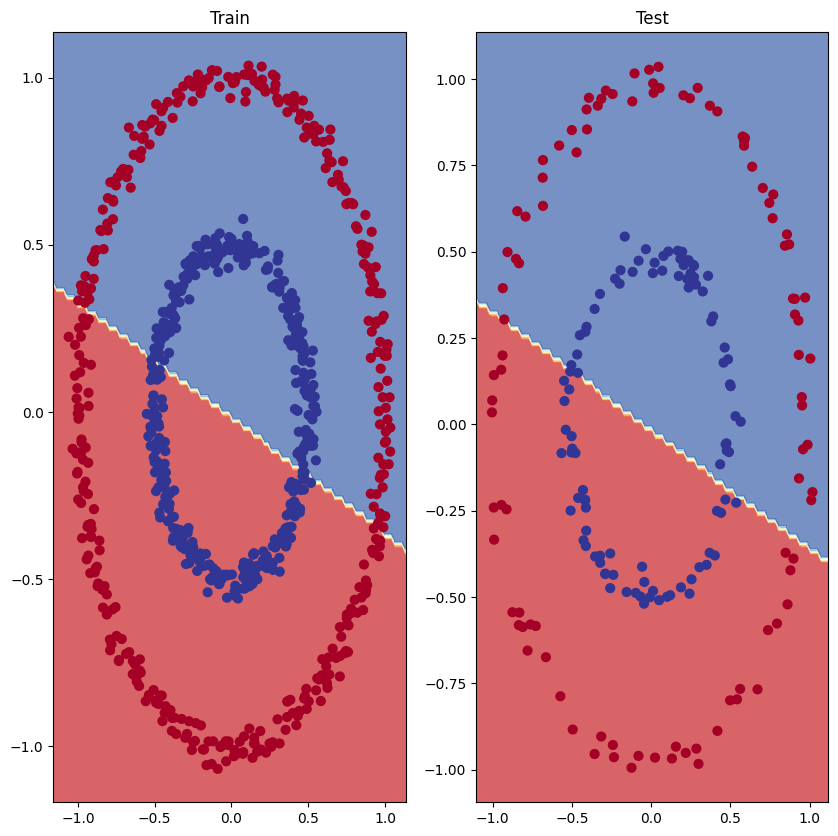

In [ ]:
from helper_functions import plot_predictions, plot_decision_boundary
plt.figure(figsize=(10,10))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model, X_train, y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model, X_test, y_test)
